
# EduPredict — Inteligência Artificial para Apoio Pedagógico

## 1. Contexto do problema

O EduPredict é um protótipo de aprendizado de máquina
voltado à análise de indicadores de desempenho escolar.

O projeto utiliza o dataset público Student Performance
Factors, disponibilizado no Kaggle, para investigar
relações entre fatores acadêmicos e o desempenho dos
estudantes.

### Objetivo

Desenvolver uma rede neural artificial do tipo
Multilayer Perceptron (MLP) para classificar faixas
de desempenho acadêmico a partir de variáveis
disponíveis no conjunto de dados.

### Aplicação prática

O modelo poderá servir como demonstração de uma
ferramenta de apoio à análise pedagógica.

As previsões não devem ser utilizadas isoladamente
para decisões sobre estudantes.

### Fonte dos dados

https://www.kaggle.com/datasets/lainguyn123/student-performance-factors

### Tecnologias

- Python
- Pandas e NumPy
- Scikit-learn
- Matplotlib e Seaborn
- Jupyter Notebook
- FastAPI
- UV


In [2]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("EduPredict — Ambiente de análise inicializado!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)


EduPredict — Ambiente de análise inicializado!
Pandas: 3.1.1
NumPy: 2.5.5


In [3]:

# Localizar a raiz do projeto
diretorio_atual = Path.cwd()

if (diretorio_atual / "data" / "dataset.csv").exists():
    caminho_dataset = diretorio_atual / "data" / "dataset.csv"
elif (diretorio_atual.parent / "data" / "dataset.csv").exists():
    caminho_dataset = diretorio_atual.parent / "data" / "dataset.csv"
else:
    raise FileNotFoundError(
        "Arquivo data/dataset.csv não encontrado."
    )

df = pd.read_csv(caminho_dataset)

print("Dataset carregado com sucesso!")
print(f"Registros: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

display(df.head())


Dataset carregado com sucesso!
Registros: 6607
Colunas: 20


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [4]:

print("=== COLUNAS DISPONÍVEIS ===")
print(df.columns.tolist())

print("\n=== TIPOS DE DADOS ===")
display(df.dtypes.to_frame("Tipo"))

print("\n=== VALORES AUSENTES ===")
display(df.isnull().sum().to_frame("Nulos"))

print("\n=== ESTATÍSTICAS DESCRITIVAS ===")
display(df.describe(include="all").T)


=== COLUNAS DISPONÍVEIS ===
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

=== TIPOS DE DADOS ===


,Tipo
Hours_Studied,int64
Attendance,int64
Parental_Involvement,str
Access_to_Resources,str
Extracurricular_Activities,str
Sleep_Hours,int64
Previous_Scores,int64
Motivation_Level,str
Internet_Access,str
Tutoring_Sessions,int64



=== VALORES AUSENTES ===


,Nulos
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0



=== ESTATÍSTICAS DESCRITIVAS ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,NaN,NaN,NaN,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,NaN,NaN,NaN,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Parental_Involvement,6607,3,Medium,3362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Access_to_Resources,6607,3,Medium,3319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracurricular_Activities,6607,2,Yes,3938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Hours,6607.0,NaN,NaN,NaN,7.02906,1.46812,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,NaN,NaN,NaN,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Motivation_Level,6607,3,Medium,3351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet_Access,6607,2,Yes,6108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tutoring_Sessions,6607.0,NaN,NaN,NaN,1.493719,1.23057,0.0,1.0,1.0,2.0,8.0


In [5]:

print("=== QUALIDADE DO DATASET ===")

print(f"Total de registros: {len(df)}")
print(f"Registros duplicados: {df.duplicated().sum()}")

nulos = df.isna().sum()
percentuais = (nulos / len(df) * 100).round(2)

qualidade = pd.DataFrame({
    "Valores ausentes": nulos,
    "Percentual (%)": percentuais
})

display(qualidade[qualidade["Valores ausentes"] > 0])

print("\n=== DISTRIBUIÇÃO DA NOTA ===")
display(df["Exam_Score"].describe())


=== QUALIDADE DO DATASET ===
Total de registros: 6607
Registros duplicados: 0


,Valores ausentes,Percentual (%)
Teacher_Quality,78,1.18
Parental_Education_Level,90,1.36
Distance_from_Home,67,1.01



=== DISTRIBUIÇÃO DA NOTA ===


count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

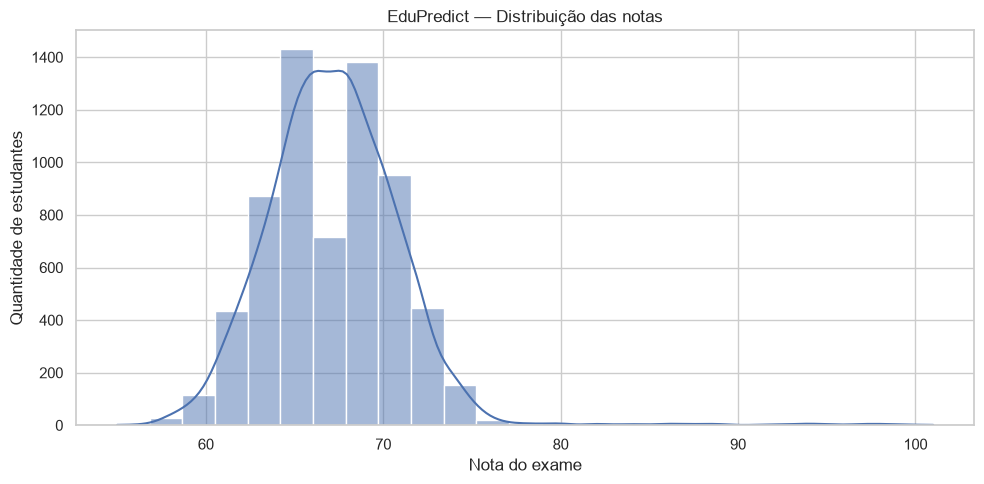

In [6]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Exam_Score",
    bins=25,
    kde=True
)

plt.title("EduPredict — Distribuição das notas")
plt.xlabel("Nota do exame")
plt.ylabel("Quantidade de estudantes")
plt.tight_layout()
plt.show()


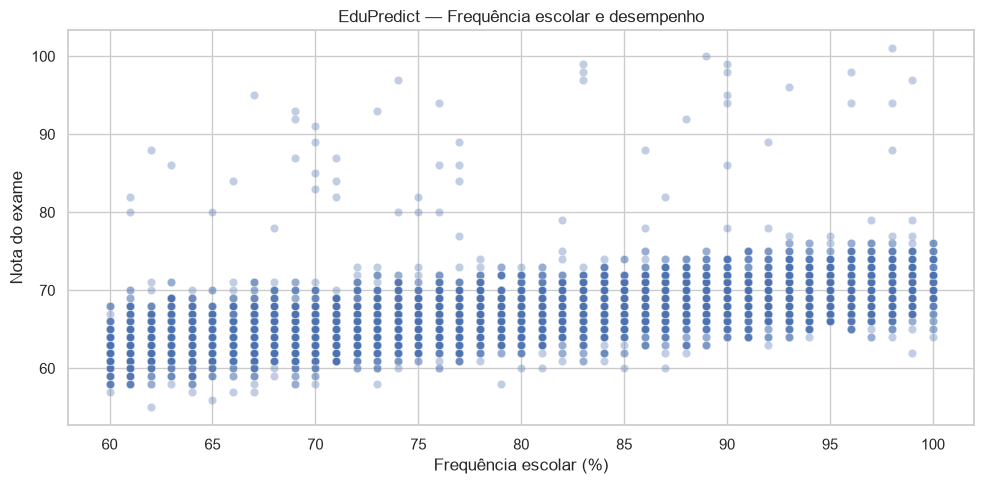

,Hours_Studied,Attendance,Previous_Scores,Exam_Score
Hours_Studied,1.000000,-0.009908,0.024846,0.445455
Attendance,-0.009908,1.000000,-0.020186,0.581072
Previous_Scores,0.024846,-0.020186,1.000000,0.175079
Exam_Score,0.445455,0.581072,0.175079,1.000000


In [7]:

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="Attendance",
    y="Exam_Score",
    alpha=0.35
)

plt.title("EduPredict — Frequência escolar e desempenho")
plt.xlabel("Frequência escolar (%)")
plt.ylabel("Nota do exame")
plt.tight_layout()
plt.show()

correlacao = df[
    ["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"]
].corr()

display(correlacao)


In [8]:

notas = df["Exam_Score"].dropna()

q33 = notas.quantile(1 / 3)
q67 = notas.quantile(2 / 3)

print("=== PONTOS DE CORTE ===")
print(f"Percentil 33,3%: {q33:.2f}")
print(f"Percentil 66,7%: {q67:.2f}")

print("\n=== NOTAS MAIS FREQUENTES ===")
display(notas.value_counts().head(15).to_frame("Quantidade"))

print("\n=== VALORES DISTINTOS ===")
print(notas.nunique())


=== PONTOS DE CORTE ===
Percentil 33,3%: 66.00
Percentil 66,7%: 69.00

=== NOTAS MAIS FREQUENTES ===


,Quantidade
Exam_Score,
68,759
66,751
67,717
65,679
69,624
70,542
64,501
71,408
63,371



=== VALORES DISTINTOS ===
45
